# Visualize Weka speed data

In [1]:
# Imports
import json

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from dataclasses import dataclass, asdict
from pathlib import Path

from weka_helpers import PrimitiveResultMap, ResultMap, convert_results_to_primitive, load_results_from_json

In [2]:
# Input parameters

input_dir = Path("/rubin/bench/weka")

input_files: list[Path] = input_dir.glob("*.json")

In [3]:
def result_map_to_dataframe(result_map: ResultMap) -> pd.DataFrame:
    rmd = {
        "sizes": result_map.sizes,
        "initial_speeds": result_map.initial_speeds,
        "recheck_speeds": result_map.recheck_speeds,
        "ratios": result_map.ratios
    }
    return pd.DataFrame(data=rmd)
    
def plot_result(result_map: ResultMap) -> None:
    plot_recheck = any(result_map.recheck_speeds)
    plot_ratio = any(result_map.ratios)
    plot_individual_speeds(result_map, plot_recheck)
    

def plot_individual_speeds(result_map: ResultMap,
                          plot_recheck: bool) -> None:
    df = result_map_to_dataframe(result_map)
    fig = make_subplots(specs=[[{"secondary_y": True}]])
    xsz=len(df.initial_speeds)
    if plot_recheck:
        assert xsz == len(df.recheck_speeds)
    xrange=list(range(xsz))
    fig.add_trace(
        go.Scatter(
            x=xrange,
            y=df.initial_speeds,name="Initial speed"
        ),
        secondary_y=False
    )
    if plot_recheck:
        fig.add_trace(
            go.Scatter(
                x=xrange,
                y=df.recheck_speeds,
                name="Recheck speed"
            ),
            secondary_y=True
        )
    fig.update_layout(
        title_text = "Weka S3 Gateway speed"
    )
    fig.update_yaxes(title_text="Initial speed (bytes/s)",
                     secondary_y=False)
    if plot_recheck:
        fig.update_yaxes(title_text="Recheck speed (bytes/s)",
                         secondary_y=True)
    fig.show()    

/rubin/bench/weka/weka-gateway-2026.10.09.23.15.00-adam.json
[ResultMap(display_name='datasets', dataset_name='visit_image', initial_statistics=ResultStatistics(CV=0.08063954676988257, mean=4565606.4, median=4753408.0, pvariance=135547993456.64, pstdev=368168.4308256752), object_size_statistics=ResultStatistics(CV=0.0796064622099097, mean=23810112, median=24154560, pvariance=3592688173056, pstdev=1895438.7811417177), recheck_statistics=ResultStatistics(CV=0.7155592984813589, mean=9875865.6, median=6481920.0, pvariance=49939202342649.86, pstdev=7066767.4606321845), ratio_statistics=ResultStatistics(CV=0.7451956631181349, mean=2.1973338529808033, median=1.3519863306279367, pvariance=2.681221732023915, pstdev=1.6374436576639562), result_items=[ResultMapItem(url='https://sdfdatas3.slac.stanford.edu/rubin-dp2/LSSTCam/runs/DRP/DP2/v30_0_11/DM-55926/visit_image_rewrite/20260828T205140Z/visit_image/20250520/z/z_20/2025052000347/visit_image_LSSTCam_z_z_20_2025052000347_R01_S01_LSSTCam_runs_DRP_

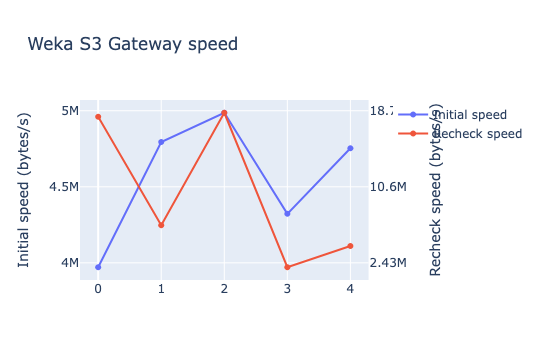

In [4]:
# Build a list of ResultMaps from all the files
res: list[ResultMap] = []
for fn in input_files:
    print(fn)
    rms=load_results_from_json(fn)
    res.extend(rms)

print(res, len(res))

for result_map in res:
    print(result_map)
    plot_result(result_map)